# 1. Business problem

A company must source **250,000 units/year** from four suppliers. Suppliers closer to the plant have smaller replenishment batches but may require many more transport movements. More distant suppliers ship in larger batches, reducing the number of trips but increasing the inventory exposure associated with each sourcing share.

We evaluate every sourcing mix with two objectives:

- **Inventory proxy** — weighted supplier batch size. Lower is better.
- **Annual transport CO₂** — shipments × distance × emission factor. Lower is better.

The conflict is intentional: the sourcing mix that minimizes one KPI is generally not the mix that minimizes the other.

### Model quantities
For supplier $i$:

$$q_i = s_i D$$

$$n_i = \left\lceil \frac{q_i}{B_i} \right\rceil$$

$$Stock = \sum_i s_i B_i$$

$$CO_2 = \sum_i n_i d_i EF$$

where $s_i$ is sourcing share, $D$ demand, $B_i$ batch size, $d_i$ distance, and $EF$ the transport emission factor.


### 1.1 Data and assumptions


In [1]:
%pip install -q pyomo highspy


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

D = 250000
EF = 0.35

suppliers = pd.DataFrame({
    "Supplier": ["Next", "Mid", "Long", "Far"],
    "Batch":    [250, 1000, 3500, 8000],
    "Distance": [60, 150, 500, 900]
}).set_index("Supplier")

I = list(suppliers.index)
suppliers


,Batch,Distance
Supplier,,
Next,250,60
Mid,1000,150
Long,3500,500
Far,8000,900


In [3]:
import math

def evaluate_mix(shares):
    stock = 0
    co2 = 0

    for i in I:
        s = shares[i]
        batch = suppliers.loc[i, "Batch"]
        distance = suppliers.loc[i, "Distance"]

        q = round(s * D, 10)

        n_shipments = math.ceil(q / batch) if q > 0 else 0

        stock += s * batch
        co2 += n_shipments * distance * EF

    return {
        "Stock": stock,
        "CO2": co2
    }

In [4]:
test_mixes = {
    "100% Next": {"Next": 1.0, "Mid": 0.0, "Long": 0.0, "Far": 0.0},
    "100% Mid":  {"Next": 0.0, "Mid": 1.0, "Long": 0.0, "Far": 0.0},
    "100% Long": {"Next": 0.0, "Mid": 0.0, "Long": 1.0, "Far": 0.0},
    "100% Far":  {"Next": 0.0, "Mid": 0.0, "Long": 0.0, "Far": 1.0},
    "25% Each":  {"Next": 0.25, "Mid": 0.25, "Long": 0.25, "Far": 0.25}
}

results = []

for name, mix in test_mixes.items():
    metrics = evaluate_mix(mix)

    results.append({
        "Scenario": name,
        **metrics
    })

pd.DataFrame(results)

,Scenario,Stock,CO2
0,100% Next,250.000,"21,000.000"
1,100% Mid,"1,000.000","13,125.000"
2,100% Long,"3,500.000","12,600.000"
3,100% Far,"8,000.000","10,080.000"
4,25% Each,"3,187.500","14,227.500"


In [ ]:
results_df = pd.DataFrame(results).set_index("Scenario")
results_df

# ## 2. Generate feasible sourcing mixes

In [5]:
mixes = []

step = 0.05

for s_next in np.arange(0, 1 + step, step):
    for s_mid in np.arange(0, 1 - s_next + step, step):
        for s_long in np.arange(0, 1 - s_next - s_mid + step, step):

            s_far = 1 - s_next - s_mid - s_long

            if s_far < -1e-9:
                continue

            shares = {
                "Next": round(s_next, 2),
                "Mid": round(s_mid, 2),
                "Long": round(s_long, 2),
                "Far": round(max(0, s_far), 2)
            }

            metrics = evaluate_mix(shares)

            mixes.append({
                **shares,
                **metrics
            })

mix_df = pd.DataFrame(mixes)

len(mix_df)

1771

You now have 1,771 feasible sourcing mixes at 5% share increments.
The next step is to identify which of those are Pareto-efficient: solutions where you cannot improve Inventory without worsening CO₂, or improve CO₂ without worsening Inventory.

In [7]:
def is_pareto_efficient(df, stock_col="Stock", co2_col="CO2"):
    efficient = []

    for idx, row in df.iterrows():
        dominated = (
            (df[stock_col] <= row[stock_col]) &
            (df[co2_col] <= row[co2_col]) &
            (
                (df[stock_col] < row[stock_col]) |
                (df[co2_col] < row[co2_col])
            )
        ).any()

        efficient.append(not dominated)

    return efficient


mix_df["Pareto"] = is_pareto_efficient(mix_df)

pareto_df = (
    mix_df[mix_df["Pareto"]]
    .sort_values("Stock")
    .reset_index(drop=True)
)

pareto_df

,Next,Mid,Long,Far,Stock,CO2,Pareto
0,1.000,0.000,0.000,0.000,250.000,"21,000.000",True
1,0.950,0.050,0.000,0.000,287.500,"20,632.500",True
2,0.900,0.100,0.000,0.000,325.000,"20,212.500",True
3,0.850,0.150,0.000,0.000,362.500,"19,845.000",True
4,0.800,0.200,0.000,0.000,400.000,"19,425.000",True
5,0.750,0.250,0.000,0.000,437.500,"19,057.500",True
6,0.700,0.300,0.000,0.000,475.000,"18,637.500",True
7,0.650,0.350,0.000,0.000,512.500,"18,270.000",True
8,0.600,0.400,0.000,0.000,550.000,"17,850.000",True
9,0.550,0.450,0.000,0.000,587.500,"17,482.500",True


In [8]:
len(pareto_df)

52

Now we plot them

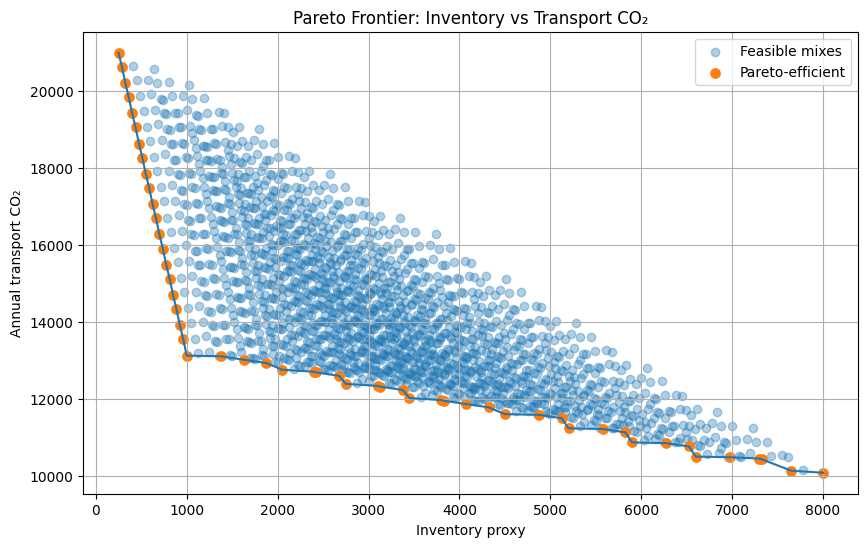

In [9]:
plt.figure(figsize=(10, 6))

# All feasible sourcing mixes
plt.scatter(
    mix_df["Stock"],
    mix_df["CO2"],
    alpha=0.35,
    label="Feasible mixes"
)

# Pareto-efficient solutions
plt.scatter(
    pareto_df["Stock"],
    pareto_df["CO2"],
    s=45,
    label="Pareto-efficient"
)

# Connect Pareto points
plt.plot(
    pareto_df["Stock"],
    pareto_df["CO2"]
)

plt.xlabel("Inventory proxy")
plt.ylabel("Annual transport CO₂")
plt.title("Pareto Frontier: Inventory vs Transport CO₂")
plt.legend()
plt.grid(True)

plt.show()

In [10]:
pareto_display = pareto_df[
    ["Next", "Mid", "Long", "Far", "Stock", "CO2"]
].copy()

pareto_display[["Next", "Mid", "Long", "Far"]] = (
    pareto_display[["Next", "Mid", "Long", "Far"]].round(2)
)

pareto_display["Stock"] = pareto_display["Stock"].round(1)
pareto_display["CO2"] = pareto_display["CO2"].round(1)

pareto_display

,Next,Mid,Long,Far,Stock,CO2
0,1.000,0.000,0.000,0.000,250.000,"21,000.000"
1,0.950,0.050,0.000,0.000,287.500,"20,632.500"
2,0.900,0.100,0.000,0.000,325.000,"20,212.500"
3,0.850,0.150,0.000,0.000,362.500,"19,845.000"
4,0.800,0.200,0.000,0.000,400.000,"19,425.000"
5,0.750,0.250,0.000,0.000,437.500,"19,057.500"
6,0.700,0.300,0.000,0.000,475.000,"18,637.500"
7,0.650,0.350,0.000,0.000,512.500,"18,270.000"
8,0.600,0.400,0.000,0.000,550.000,"17,850.000"
9,0.550,0.450,0.000,0.000,587.500,"17,482.500"


Let's see increase in CO2 production in percentages instead of numbers.

In [11]:
pareto_pct = pareto_display.copy()

for col in ["Next", "Mid", "Long", "Far"]:
    pareto_pct[col] = (pareto_pct[col] * 100).round(0).astype(int).astype(str) + "%"

pareto_pct

,Next,Mid,Long,Far,Stock,CO2
0,100%,0%,0%,0%,250.000,"21,000.000"
1,95%,5%,0%,0%,287.500,"20,632.500"
2,90%,10%,0%,0%,325.000,"20,212.500"
3,85%,15%,0%,0%,362.500,"19,845.000"
4,80%,20%,0%,0%,400.000,"19,425.000"
5,75%,25%,0%,0%,437.500,"19,057.500"
6,70%,30%,0%,0%,475.000,"18,637.500"
7,65%,35%,0%,0%,512.500,"18,270.000"
8,60%,40%,0%,0%,550.000,"17,850.000"
9,55%,45%,0%,0%,587.500,"17,482.500"


In [12]:
def is_pareto_efficient(df, stock_col="Stock", co2_col="CO2"):
    efficient = []

    for idx, row in df.iterrows():

        others = df.drop(idx)

        dominated = (
            (others[stock_col] <= row[stock_col]) &
            (others[co2_col] <= row[co2_col]) &
            (
                (others[stock_col] < row[stock_col]) |
                (others[co2_col] < row[co2_col])
            )
        ).any()

        efficient.append(not dominated)

    return efficient


mix_df["Pareto"] = is_pareto_efficient(mix_df)

pareto_df = (
    mix_df[mix_df["Pareto"]]
    .sort_values(["Stock", "CO2"])
    .reset_index(drop=True)
)

len(pareto_df)

52